# Reto C · ¿Qué se quemó? Incendios del Perú, bomberos y viviendas cercanas

**Pregunta.** En el último mes (21 de septiembre al 21 de octubre de 2026), ¿qué tipo de cobertura
se quemó en los incendios del Perú (bosque, pastizal o cultivo), cuántas edificaciones había cerca
y a qué distancia estaba la compañía de bomberos más cercana?

El cuaderno tiene dos escalas:

1. **Todo el Perú.** Focos de calor VIIRS → incendios → cobertura WorldCover de la zona con fuego,
   edificaciones de Google Open Buildings a 1 y 3 km y distancia a la compañía de bomberos más cercana.
2. **Río Tambo (Satipo, Junín), el incendio más grande de la última semana.** Área quemada con dNBR de Sentinel-2,
   cruzada con WorldCover (el Reto C propiamente dicho), con las edificaciones y con las acciones
   del Estado que reporta el COEN-INDECI.

Todas las fuentes son públicas, no piden clave y el cuaderno corre en CPU.

In [1]:
import io
import json
import os
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import rasterio
import rasterio.features
import rasterio.mask
import shapely
import shapely.geometry
import requests
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.vrt import WarpedVRT
from scipy.ndimage import binary_dilation, distance_transform_edt, label
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import radius_neighbors_graph

warnings.filterwarnings("ignore", category=UserWarning)
os.environ.update({
    "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",   # no listar carpetas remotas al abrir un archivo
    "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": ".tif,.fgb",
    "GDAL_HTTP_MAX_RETRY": "4",
    "GDAL_HTTP_RETRY_DELAY": "2",
})
pd.set_option("display.width", 160)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRUDOS, PROC, FIG, DOCS = (RAIZ / p for p in ["data/raw", "data/processed", "figuras", "docs"])
for carpeta in (CRUDOS, PROC, FIG, DOCS):
    carpeta.mkdir(parents=True, exist_ok=True)
UA = {"User-Agent": "Mozilla/5.0 (reto-c-incendios; curso Ciencia de Datos con Python)"}
CRS_PE = "ESRI:102033"  # Albers de igual área para Sudamérica: metros, sirve para áreas y distancias

# Decisiones de método: todas se reportan en el README
INICIO, FIN = pd.Timestamp("2026-09-21"), pd.Timestamp("2026-10-21")  # último mes, hora de Lima
SATELITES = ["NPP-375", "NOAA-20", "NOAA-21"]   # VIIRS, píxel de 375 m
DIST_FOCOS_M, HORAS_FOCOS = 1000, 48            # focos a <= 1 km y <= 48 h son un mismo incendio
HUELLA_MIN_HA = 100                             # incendios que entran al análisis nacional
TOP_EDIFICIOS = 20                              # los N incendios más grandes a los que se cruzan edificaciones
RADIOS_M = (1000, 3000)                         # edificaciones a 1 y 3 km de la zona con fuego
CONF_EDIFICIOS = 0.75                           # confianza mínima de Google Open Buildings
UMBRAL_DNBR = 0.27                              # quemado = severidad moderada o más (Key y Benson)

## 1. Límites y focos de calor

Los focos vienen de los archivos diarios de **INPE Queimadas** (Brasil), que redistribuye los focos
VIIRS de la NASA para toda Sudamérica sin pedir clave. Uso solo los tres satélites VIIRS
(S-NPP, NOAA-20 y NOAA-21, píxel de 375 m). Los archivos van por fecha UTC; paso todo a hora de Lima.

In [2]:
GEO = "https://raw.githubusercontent.com/juaneladio/peru-geojson/master/{}"


def leer_cacheado(nombre):
    ruta = CRUDOS / nombre
    if not ruta.exists():
        ruta.write_bytes(requests.get(GEO.format(nombre), headers=UA, timeout=120).content)
    return gpd.read_file(ruta)


distritos = leer_cacheado("peru_distrital_simple.geojson")[["IDDIST", "NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]]
departamentos = leer_cacheado("peru_departamental_simple.geojson")[["NOMBDEP", "geometry"]]

URL_INPE = "https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/diario/America_Sul/focos_diario_{:%Y%m%d}.csv"
(CRUDOS / "inpe").mkdir(exist_ok=True)
HOY_UTC = pd.Timestamp.now("UTC").tz_localize(None).normalize()


def focos_inpe(dia):
    """Un día de focos INPE (fecha UTC), solo Perú. Guarda una copia local."""
    ruta = CRUDOS / "inpe" / f"inpe_peru_{dia:%Y%m%d}.csv"
    if ruta.exists() and dia < HOY_UTC:
        return pd.read_csv(ruta)
    r = requests.get(URL_INPE.format(dia), headers=UA, timeout=300)
    if r.status_code != 200:
        return pd.DataFrame()
    d = pd.read_csv(io.StringIO(r.text))
    d = d[d.pais == "Peru"]
    d.to_csv(ruta, index=False)
    return d


dias = pd.date_range(INICIO, FIN + pd.Timedelta(days=1))  # un día más: el 21 en Lima termina el 22 en UTC
with ThreadPoolExecutor(6) as ex:
    crudos = pd.concat(list(ex.map(focos_inpe, dias)), ignore_index=True)

crudos["hora_lima"] = pd.to_datetime(crudos.data_hora_gmt) - pd.Timedelta(hours=5)
print(f"Focos INPE en el Perú, todos los satélites: {len(crudos):,}")
print(crudos.satelite.value_counts().to_string())

C:\Users\nofer\AppData\Local\Temp\ipykernel_11052\2179731995.py:33: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  dias = pd.date_range(INICIO, FIN + pd.Timedelta(days=1))  # un día más: el 21 en Lima termina el 22 en UTC


Focos INPE en el Perú, todos los satélites: 87,897
satelite
GOES-19      22843
NOAA-20      20484
NOAA-21      19845
NPP-375      19278
NPP-375D      2272
AQUA_M-T      2245
TERRA_M-M      498
TERRA_M-T      242
METOP-B         77
METOP-C         61
AQUA_M-M        52


C:\Users\nofer\AppData\Local\Temp\ipykernel_11052\2179731995.py:37: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  crudos["hora_lima"] = pd.to_datetime(crudos.data_hora_gmt) - pd.Timedelta(hours=5)


**Limpieza.** Me quedo con VIIRS dentro del periodo y dentro del Perú, y saco los focos a menos de 3 km
de los volcanes activos (Sabancaya y Ubinas): ahí el satélite ve calor, pero no es un incendio.

In [3]:
viirs = crudos[crudos.satelite.isin(SATELITES)
               & (crudos.hora_lima >= INICIO) & (crudos.hora_lima < FIN + pd.Timedelta(days=1))]
viirs = viirs.drop_duplicates("id")
focos = gpd.GeoDataFrame(viirs, geometry=gpd.points_from_xy(viirs.lon, viirs.lat), crs=4326)
focos = gpd.sjoin(focos, distritos, predicate="within").drop(columns="index_right")
focos = focos.to_crs(CRS_PE)
focos["frp"] = focos.frp.where(focos.frp >= 0)

VOLCANES = {"Sabancaya": (-71.857, -15.787), "Ubinas": (-70.903, -16.355)}
volcanes = gpd.GeoSeries(gpd.points_from_xy(*zip(*VOLCANES.values())), crs=4326).to_crs(CRS_PE)
cerca_volcan = np.zeros(len(focos), bool)
for v in volcanes:
    cerca_volcan |= (focos.distance(v) < 3000).to_numpy()
focos = focos[~cerca_volcan].reset_index(drop=True)

print(f"Focos VIIRS en el Perú, {INICIO:%d/%m} al {FIN:%d/%m/%Y}: {len(focos):,} "
      f"(se quitaron {cerca_volcan.sum()} junto a volcanes)")
print(f"Último foco: {focos.hora_lima.max():%d/%m/%Y %H:%M} (hora de Lima)")

C:\Users\nofer\AppData\Local\Temp\ipykernel_11052\3262457892.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  & (crudos.hora_lima >= INICIO) & (crudos.hora_lima < FIN + pd.Timedelta(days=1))]


Focos VIIRS en el Perú, 21/09 al 21/10/2026: 59,375 (se quitaron 1 junto a volcanes)
Último foco: 21/10/2026 14:19 (hora de Lima)


## 2. De focos a incendios

Un foco es un píxel de 375 m donde el satélite vio fuego; no es un incendio. Uno dos focos en el mismo
incendio cuando están a **≤ 1 km y ≤ 48 h** entre sí (y en cadena: si A toca a B y B toca a C, los tres
son el mismo incendio). La **huella** es la unión de los píxeles de 375 m: sirve para comparar
incendios entre sí, pero no es el área quemada.

In [4]:
def agrupar(focos, dist_m=DIST_FOCOS_M, horas=HORAS_FOCOS):
    xy = np.c_[focos.geometry.x, focos.geometry.y]
    vecinos = radius_neighbors_graph(xy, dist_m, mode="connectivity").tocoo()
    h = focos.hora_lima.to_numpy().astype("datetime64[h]").astype(np.int64)
    ok = np.abs(h[vecinos.row] - h[vecinos.col]) <= horas
    grafo = coo_matrix((np.ones(ok.sum()), (vecinos.row[ok], vecinos.col[ok])), shape=vecinos.shape)
    return connected_components(grafo, directed=False)[1]


def moda(s):
    return s.mode().iat[0] if s.notna().any() else None


focos["incendio"] = agrupar(focos)
huellas = focos.set_geometry(focos.buffer(375 / 2, cap_style="square")).dissolve("incendio").geometry
incendios = focos.groupby("incendio").agg(
    focos=("id", "size"), inicio=("hora_lima", "min"), fin=("hora_lima", "max"), frp_mw=("frp", "sum"),
    departamento=("NOMBDEP", moda), provincia=("NOMBPROV", moda), distrito=("NOMBDIST", moda),
    ubigeo=("IDDIST", moda),
)
incendios = gpd.GeoDataFrame(incendios, geometry=huellas.reindex(incendios.index), crs=CRS_PE)
incendios["huella_ha"] = incendios.area / 1e4
incendios["dias"] = (incendios.fin - incendios.inicio).dt.total_seconds() / 86400
incendios["activo_24h"] = incendios.fin >= focos.hora_lima.max() - pd.Timedelta(hours=24)
incendios = incendios.sort_values("huella_ha", ascending=False)

grandes = incendios[incendios.huella_ha >= HUELLA_MIN_HA].copy()
print(f"{len(incendios):,} incendios; {len(grandes)} con huella ≥ {HUELLA_MIN_HA} ha; "
      f"{incendios.activo_24h.sum()} con focos en las últimas 24 h")
grandes.drop(columns="geometry").head(15).round(1)

18,744 incendios; 730 con huella ≥ 100 ha; 176 con focos en las últimas 24 h


C:\Users\nofer\AppData\Local\Temp\ipykernel_11052\397127639.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  incendios["activo_24h"] = incendios.fin >= focos.hora_lima.max() - pd.Timedelta(hours=24)


,focos,inicio,fin,frp_mw,departamento,provincia,distrito,ubigeo,huella_ha,dias,activo_24h
incendio,,,,,,,,,,,
11277,679,2026-10-06 13:00:00,2026-10-19 13:11:00,9929.9,APURIMAC,ABANCAY,CURAHUASI,030104,4398.7,13.0,False
15457,366,2026-10-13 13:06:00,2026-10-17 13:49:00,3665.3,JUNIN,SATIPO,RIO TAMBO,120608,2016.4,4.0,False
8777,174,2026-10-03 12:52:00,2026-10-07 01:03:00,1964.0,CUSCO,CANCHIS,SICUANI,080601,1723.1,3.5,False
11285,212,2026-10-06 13:00:00,2026-10-16 14:08:00,6514.6,APURIMAC,ABANCAY,SAN PEDRO DE CACHORA,030108,1514.5,10.0,False
9857,175,2026-10-05 12:34:00,2026-10-07 01:03:00,9656.3,CUSCO,ESPINAR,ALTO PICHIGUA,080808,1370.6,1.5,False
17881,178,2026-10-16 14:08:00,2026-10-18 14:13:00,1972.5,AREQUIPA,CONDESUYOS,CHICHAS,040604,1325.8,2.0,False
7944,173,2026-10-01 12:54:00,2026-10-06 13:56:00,3734.6,APURIMAC,COTABAMBAS,COYLLURQUI,030503,1171.9,5.0,False
14240,112,2026-10-09 13:43:00,2026-10-10 14:00:00,1436.6,AREQUIPA,AREQUIPA,LA JOYA,040108,1108.1,1.0,False
8316,172,2026-10-02 12:34:00,2026-10-06 13:56:00,4368.2,AYACUCHO,PARINACOCHAS,CHUMPI,050702,1080.3,4.1,False


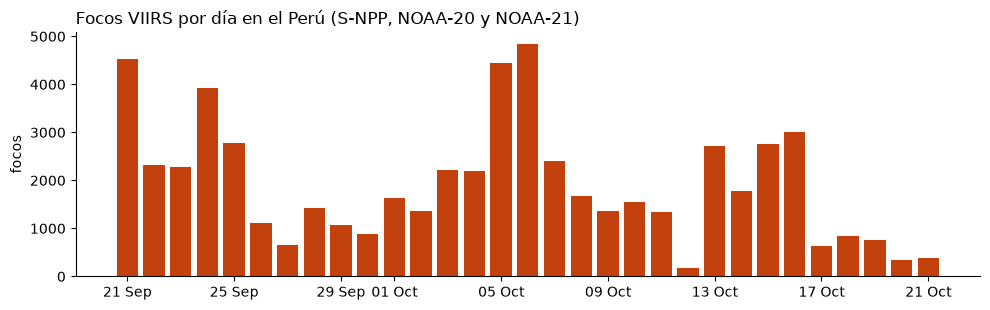

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.2))
por_dia = focos.groupby(focos.hora_lima.dt.floor("D")).size()
ax.bar(por_dia.index, por_dia.values, color="#c2410c", width=0.8)
ax.set_title("Focos VIIRS por día en el Perú (S-NPP, NOAA-20 y NOAA-21)", loc="left")
ax.set_ylabel("focos")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "focos_por_dia.png", dpi=150)
plt.show()

## 3. Bomberos: la compañía más cercana

Las compañías del Cuerpo General de Bomberos Voluntarios del Perú (CGBVP) salen de **OpenStreetMap**
(`amenity=fire_station`), consultado con Overpass. La distancia es en línea recta desde el borde de la
huella: el trayecto real por carretera o río es más largo.

In [6]:
ruta_bomberos = CRUDOS / "bomberos_osm.json"
if not ruta_bomberos.exists():
    consulta = ('[out:json][timeout:180];area["ISO3166-1"="PE"][admin_level=2]->.pe;'
                'nwr["amenity"="fire_station"](area.pe);out center tags;')
    # Overpass responde 406 a un User-Agent que imita a un navegador; con uno propio sí responde
    r = requests.post("https://overpass-api.de/api/interpreter", data={"data": consulta},
                      headers={"User-Agent": "reto-c-incendios/0.1"}, timeout=300)
    r.raise_for_status()
    ruta_bomberos.write_text(r.text, encoding="utf-8")

elementos = json.loads(ruta_bomberos.read_text(encoding="utf-8"))["elements"]
bomberos = pd.DataFrame([{
    "nombre": e.get("tags", {}).get("name", "Estación sin nombre en OSM"),
    "osm": f"{e['type']}/{e['id']}",
    "lon": e.get("lon", e.get("center", {}).get("lon")),
    "lat": e.get("lat", e.get("center", {}).get("lat")),
} for e in elementos])
bomberos = gpd.GeoDataFrame(bomberos, geometry=gpd.points_from_xy(bomberos.lon, bomberos.lat), crs=4326)
bomberos = gpd.sjoin(bomberos, distritos[["NOMBDEP", "geometry"]], predicate="within").drop(columns="index_right")
bomberos = bomberos.to_crs(CRS_PE)
print(f"{len(bomberos)} estaciones de bomberos en OSM")
print(bomberos.NOMBDEP.value_counts().head(8).to_string())

cerca = gpd.sjoin_nearest(grandes[["geometry"]], bomberos[["nombre", "geometry"]], distance_col="dist_m")
cerca = cerca[~cerca.index.duplicated()]
grandes["bomberos"] = cerca.nombre
grandes["dist_bomberos_km"] = cerca.dist_m / 1000
TRAMOS = [0, 10, 30, 60, np.inf]
ETIQ_TRAMOS = ["≤ 10 km", "10 a 30 km", "30 a 60 km", "más de 60 km"]
grandes["tramo_bomberos"] = pd.cut(grandes.dist_bomberos_km, TRAMOS, labels=ETIQ_TRAMOS, include_lowest=True)
grandes.groupby("tramo_bomberos", observed=False).agg(incendios=("focos", "size"), huella_ha=("huella_ha", "sum")).round(0)

224 estaciones de bomberos en OSM
NOMBDEP
LIMA           54
TACNA          17
LA LIBERTAD    13
CALLAO         13
AREQUIPA       12
PIURA          12
ICA            11
CUSCO           9


,incendios,huella_ha
tramo_bomberos,,
≤ 10 km,42,13692.0
10 a 30 km,185,46390.0
30 a 60 km,237,51699.0
más de 60 km,266,49391.0


## 4. Edificaciones cerca del fuego (Google Open Buildings)

Google Open Buildings v3 detecta techos en imágenes satelitales (de alrededor de 2022-2023). Lo leo
desde la copia en FlatGeobuf de VIDA en Source Cooperative: ese formato tiene índice espacial, así que
se baja solo el pedazo que rodea a cada incendio y no los 5,6 GB del Perú. Me quedo con los polígonos
de Google con confianza ≥ 0,75. Una edificación no siempre es una vivienda (puede ser un almacén o
un corral techado), pero en el campo la mayoría lo son.

Para no tardar demasiado, cruzo los 20 incendios más grandes y uso radios de 1 y 3 km: cerca de una
ciudad (Pucallpa, por ejemplo) un radio de 5 km obliga a bajar decenas de miles de techos por incendio.

In [7]:
URL_EDIFICIOS = ("/vsicurl/https://data.source.coop/vida/google-microsoft-open-buildings/"
                 "flatgeobuf/by_country/country_iso=PER/PER.fgb")


def leer_edificios(geom, margen_m):
    """Edificaciones de Google (confianza >= CONF_EDIFICIOS) a menos de margen_m de geom, en CRS_PE."""
    zona = gpd.GeoSeries([geom.buffer(margen_m)], crs=CRS_PE).to_crs(4326)
    e = pyogrio.read_dataframe(URL_EDIFICIOS, bbox=tuple(zona.total_bounds),
                               columns=["bf_source", "confidence", "area_in_meters"])
    e = e[(e.bf_source == "google") & (e.confidence >= CONF_EDIFICIOS)]
    return e.to_crs(CRS_PE)


def contar_edificios(item):
    idx, geom = item
    centros = leer_edificios(geom, max(RADIOS_M)).centroid
    d = centros.distance(geom)
    fila = {"incendio": idx, "edif_dentro": int((d == 0).sum())}
    fila |= {f"edif_{r // 1000}km": int((d <= r).sum()) for r in RADIOS_M}
    return fila


ruta_edif = PROC / "edificaciones_por_incendio.csv"
previos = pd.read_csv(ruta_edif).set_index("clave") if ruta_edif.exists() else pd.DataFrame()
seleccion = grandes.head(TOP_EDIFICIOS)
claves = seleccion.apply(lambda f: f"{f.inicio:%Y%m%d%H%M}_{f.focos}_{f.huella_ha:.0f}", axis=1)
faltan = [(i, g) for i, g, c in zip(seleccion.index, seleccion.geometry, claves) if c not in previos.index]
print(f"Leyendo edificaciones para {len(faltan)} incendios (los demás ya estaban guardados)…")
with ThreadPoolExecutor(4) as ex:
    pendientes = [ex.submit(contar_edificios, item) for item in faltan]
    for k, tarea in enumerate(as_completed(pendientes), 1):
        fila = tarea.result()
        fila["clave"] = claves.loc[fila["incendio"]]
        previos = pd.concat([previos, pd.DataFrame([fila]).set_index("clave")])
        previos.to_csv(ruta_edif)  # guarda cada incendio para no perder lo avanzado
        print(f"  {k}/{len(faltan)}", flush=True)

edif = previos.loc[previos.index.intersection(claves)]
edif = edif.set_index(claves.reset_index().set_index(0).loc[edif.index, "incendio"].to_numpy())
grandes = grandes.join(edif.drop(columns="incendio"))
cols = ["departamento", "distrito", "huella_ha", "focos", "edif_dentro", "edif_1km", "edif_3km", "dist_bomberos_km"]
grandes[cols].head(TOP_EDIFICIOS).sort_values("edif_1km", ascending=False).head(12).round(1)

Leyendo edificaciones para 0 incendios (los demás ya estaban guardados)…


,departamento,distrito,huella_ha,focos,edif_dentro,edif_1km,edif_3km,dist_bomberos_km
incendio,,,,,,,,
8777,CUSCO,SICUANI,1723.1,174,393.0,3114.0,16936.0,2.6
8448,CUSCO,URUBAMBA,836.4,102,247.0,1762.0,4390.0,5.4
14961,MOQUEGUA,SAN CRISTOBAL,934.7,130,1.0,530.0,1896.0,40.7
8316,AYACUCHO,CHUMPI,1080.3,172,4.0,429.0,1639.0,127.4
9252,CUSCO,CAPACMARCA,903.1,120,10.0,390.0,1485.0,33.0
13625,APURIMAC,GAMARRA,821.6,89,52.0,380.0,1103.0,31.7
7944,APURIMAC,COYLLURQUI,1171.9,173,154.0,260.0,652.0,35.2
9144,HUANUCO,YUYAPICHIS,931.5,95,31.0,127.0,266.0,93.0
3086,PUNO,CABANILLAS,845.8,80,13.0,120.0,335.0,44.4


## 5. ¿Qué cobertura tenía la zona con fuego? (ESA WorldCover 2021, 10 m)

WorldCover clasifica cada píxel de 10 m en bosque, matorral, pastizal, cultivo, etc. Leo las teselas
desde el bucket público de la ESA en AWS (sin clave). Aquí calculo la composición de la **huella** de
cada incendio; el área realmente quemada se mide con Sentinel-2 en la sección 7.

In [8]:
URL_WC = ("/vsicurl/https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/"
          "ESA_WorldCover_10m_2021_v200_{}_Map.tif")
CLASES_WC = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Zona construida",
             60: "Suelo desnudo", 70: "Nieve y hielo", 80: "Agua", 90: "Humedal", 95: "Manglar",
             100: "Musgos y líquenes"}
COLORES_WC = {"Bosque": "#2f6b2f", "Matorral": "#b39b2e", "Pastizal": "#e3c76b", "Cultivo": "#d9467a",
              "Zona construida": "#5b5b5b", "Suelo desnudo": "#b7a99a", "Nieve y hielo": "#dfe9f2",
              "Agua": "#3b7fc4", "Humedal": "#4fa3a0", "Manglar": "#1b8a5a", "Musgos y líquenes": "#c9d9a0"}


def teselas_wc(minx, miny, maxx, maxy):
    """Nombres de las teselas de 3° x 3° de WorldCover (esquina suroeste) que tocan la caja."""
    lats = range(int(np.floor(miny / 3) * 3), int(np.floor(maxy / 3) * 3) + 1, 3)
    lons = range(int(np.floor(minx / 3) * 3), int(np.floor(maxx / 3) * 3) + 1, 3)
    return [f"{'S' if la < 0 else 'N'}{abs(la):02d}{'W' if lo < 0 else 'E'}{abs(lo):03d}" for la in lats for lo in lons]


def composicion_wc(item):
    idx, geom = item
    g = gpd.GeoSeries([geom], crs=CRS_PE).to_crs(4326).iloc[0]
    cuenta = pd.Series(dtype=float)
    for t in teselas_wc(*g.bounds):
        try:
            with rasterio.open(URL_WC.format(t)) as src:
                a, _ = rasterio.mask.mask(src, [g], crop=True, nodata=0)
        except (rasterio.errors.RasterioIOError, ValueError):  # tesela inexistente o sin traslape
            continue
        valores, n = np.unique(a[a > 0], return_counts=True)
        cuenta = cuenta.add(pd.Series(n, index=valores), fill_value=0)
    return idx, (cuenta / cuenta.sum()).rename(CLASES_WC)


ruta_wc = PROC / "cobertura_huella_por_incendio.csv"
if ruta_wc.exists() and set(grandes.index) <= set(pd.read_csv(ruta_wc, index_col=0).index):
    comp = pd.read_csv(ruta_wc, index_col=0).loc[grandes.index]
else:
    with ThreadPoolExecutor(8) as ex:
        comp = pd.DataFrame(dict(ex.map(composicion_wc, zip(grandes.index, grandes.geometry)))).T.fillna(0)
    comp.to_csv(ruta_wc)
comp = comp.loc[grandes.index]
grandes["cobertura_principal"] = comp.idxmax(axis=1)
grandes["pct_principal"] = comp.max(axis=1) * 100

ha_por_clase = comp.mul(grandes.huella_ha, axis=0).sum().sort_values(ascending=False)
print("Huella de los incendios ≥ 100 ha según la cobertura de 2021 (ha):")
print(ha_por_clase[ha_por_clase > 0].round(0).to_string())

Huella de los incendios ≥ 100 ha según la cobertura de 2021 (ha):
Pastizal             90376.0
Bosque               53857.0
Matorral              8869.0
Suelo desnudo         5117.0
Agua                  1386.0
Cultivo               1202.0
Zona construida        249.0
Humedal                116.0
Musgos y líquenes        0.0


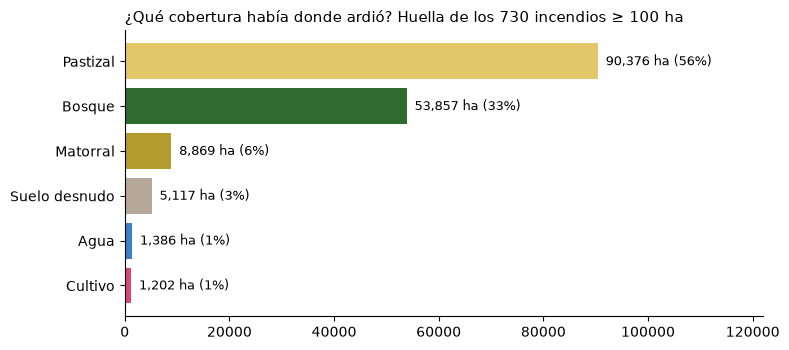

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
top = ha_por_clase[ha_por_clase / ha_por_clase.sum() > 0.005]
ax.barh(top.index[::-1], top.values[::-1], color=[COLORES_WC[c] for c in top.index[::-1]])
for y, v in enumerate(top.values[::-1]):
    ax.text(v, y, f"  {v:,.0f} ha ({v / ha_por_clase.sum():.0%})", va="center", fontsize=9)
ax.set_title(f"¿Qué cobertura había donde ardió? Huella de los {len(grandes)} incendios ≥ 100 ha",
             loc="left", fontsize=11)
ax.set_xlim(0, top.max() * 1.35)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "cobertura_nacional.png", dpi=150)
plt.show()

## 6. Mapa nacional

Cada incendio ≥ 100 ha, coloreado por la distancia a la compañía de bomberos más cercana.

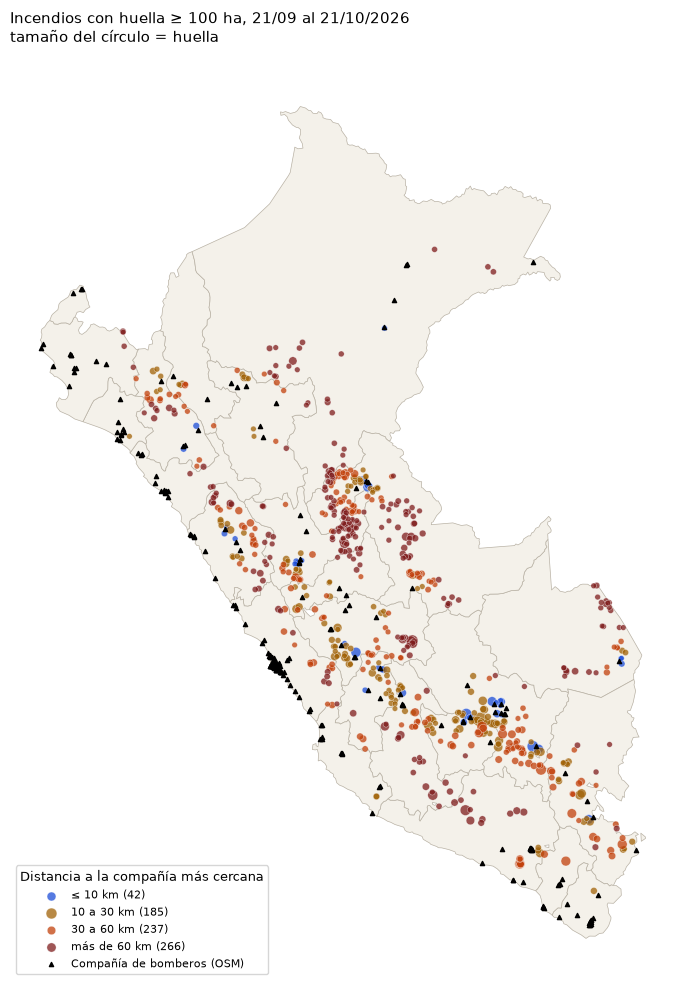

In [10]:
COLORES_TRAMO = dict(zip(ETIQ_TRAMOS, ["#1d4ed8", "#a16207", "#c2410c", "#7f1d1d"]))
fig, ax = plt.subplots(figsize=(8, 10))
departamentos.to_crs(CRS_PE).plot(ax=ax, color="#f4f1ea", edgecolor="#b9b2a5", linewidth=0.5)
centros = grandes.copy()
centros["geometry"] = grandes.centroid
for tramo, color in COLORES_TRAMO.items():
    sub = centros[centros.tramo_bomberos == tramo]
    sub.plot(ax=ax, markersize=np.sqrt(sub.huella_ha) * 1.6, color=color, alpha=0.75,
             label=f"{tramo} ({len(sub)})", edgecolor="white", linewidth=0.3)
bomberos.plot(ax=ax, marker="^", color="black", markersize=9, label="Compañía de bomberos (OSM)")
ax.legend(title="Distancia a la compañía más cercana", loc="lower left", fontsize=8, title_fontsize=9)
ax.set_title(f"Incendios con huella ≥ 100 ha, {INICIO:%d/%m} al {FIN:%d/%m/%Y}\n"
             "tamaño del círculo = huella", loc="left", fontsize=11)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(FIG / "mapa_nacional.png", dpi=150)
plt.show()

In [11]:
mapa = folium.Map(location=[-10, -75], zoom_start=6, tiles="CartoDB positron")
capa_inc = grandes.to_crs(4326).copy()
capa_inc["geometry"] = capa_inc.simplify(0.001)
for idx, f in capa_inc.iterrows():
    color = COLORES_TRAMO.get(f.tramo_bomberos, "#555")
    texto = (f"<b>{f.distrito.title()}, {f.provincia.title()} ({f.departamento.title()})</b><br>"
             f"Huella: {f.huella_ha:,.0f} ha · {f.focos} focos<br>{f.inicio:%d/%m} al {f.fin:%d/%m}<br>"
             f"Bomberos más cercanos: {f.bomberos} a {f.dist_bomberos_km:.0f} km<br>"
             f"Edificaciones a 1 km: {'' if pd.isna(f.edif_1km) else int(f.edif_1km)}<br>"
             f"Cobertura principal: {f.cobertura_principal} ({f.pct_principal:.0f} %)")
    folium.GeoJson(f.geometry.__geo_interface__, style_function=lambda _, c=color: {
        "color": c, "fillColor": c, "weight": 1, "fillOpacity": 0.6}, tooltip=folium.Tooltip(texto)).add_to(mapa)
for _, b in bomberos.to_crs(4326).iterrows():
    folium.CircleMarker([b.geometry.y, b.geometry.x], radius=3, color="black", fill=True,
                        tooltip=b.nombre).add_to(mapa)
mapa.save(FIG / "mapa_interactivo.html")
mapa

## 7. Zoom a Río Tambo (Satipo, Junín)

Fue el incendio más grande de la última semana. En el mes completo, el incendio individual más extenso
fue el de Curahuasi (Apurímac), que ya se midió en clase; por eso el zoom va a Río Tambo.

El COEN-INDECI fecha el inicio el **4 de octubre** en la comunidad nativa asháninka de Tsyapo. El fuego
se partió en varios frentes (Tsyapo, Cutivireni, Tincareni, Alto Cobeja), así que tomo como
**complejo** todos los incendios del distrito a ≤ 10 km del más grande.

In [12]:
INICIO_RT = pd.Timestamp("2026-10-04")  # fecha de inicio según el COEN
rio_tambo = incendios[incendios.distrito == "RIO TAMBO"]
principal = rio_tambo.iloc[0]
# Sin el filtro de fecha entran quemas agrícolas chicas de fines de septiembre en el mismo valle
complejo = rio_tambo[(rio_tambo.distance(principal.geometry) <= 10_000) & (rio_tambo.fin >= INICIO_RT)]
focos_rt = focos[focos.incendio.isin(complejo.index)]
print(f"Complejo Río Tambo: {len(complejo)} incendios, {len(focos_rt)} focos, "
      f"huella {complejo.huella_ha.sum():,.0f} ha, del {focos_rt.hora_lima.min():%d/%m %H:%M} "
      f"al {focos_rt.hora_lima.max():%d/%m %H:%M}")
print("El COEN registra el inicio el 04/10 a las 14:25 en la comunidad nativa de Tsyapo")

CRS_UTM, RES = "EPSG:32718", 20
zona_utm = gpd.GeoSeries([complejo.union_all()], crs=CRS_PE).to_crs(CRS_UTM).buffer(2000)
x0, y0, x1, y1 = zona_utm.total_bounds
x0, y0 = np.floor([x0 / RES, y0 / RES]) * RES
x1, y1 = np.ceil([x1 / RES, y1 / RES]) * RES
ANCHO, ALTO = int((x1 - x0) / RES), int((y1 - y0) / RES)
TRANSF = from_origin(x0, y1, RES, RES)
bbox_4326 = tuple(zona_utm.to_crs(4326).total_bounds)
print(f"Grilla de {ANCHO} x {ALTO} píxeles de 20 m ({ANCHO * ALTO * 0.04:,.0f} ha)")

Complejo Río Tambo: 30 incendios, 739 focos, huella 4,816 ha, del 03/10 13:11 al 20/10 14:13
El COEN registra el inicio el 04/10 a las 14:25 en la comunidad nativa de Tsyapo
Grilla de 1209 x 1344 píxeles de 20 m (64,996 ha)


### 7.1 Imágenes Sentinel-2: fechas y nubes antes de calcular

Sentinel-2 L2A desde **Earth Search (Element 84, AWS)**, sin clave. Planetary Computer, la fuente que
sugiere el profesor, respondía con error 502 el 21 de octubre. Para cada imagen mido la nube **dentro
de la zona** con la capa SCL: el % de nube de la escena completa (110 km) no dice nada de este valle.

In [13]:
def buscar_s2(desde, hasta):
    cuerpo = {"collections": ["sentinel-2-l2a"], "bbox": list(bbox_4326), "limit": 100,
              "datetime": f"{desde}T00:00:00Z/{hasta}T23:59:59Z"}
    r = requests.post("https://earth-search.aws.element84.com/v1/search", json=cuerpo, timeout=120)
    r.raise_for_status()
    return r.json()["features"]


def leer_en_grilla(href, resampling):
    with rasterio.open(href) as src, WarpedVRT(src, crs=CRS_UTM, transform=TRANSF, width=ANCHO, height=ALTO,
                                               resampling=resampling, src_nodata=0, nodata=0) as vrt:
        return vrt.read(1)


mascara_zona = rasterio.features.geometry_mask(zona_utm, (ALTO, ANCHO), TRANSF, invert=True)
NUBE = [3, 8, 9, 10]            # SCL: sombra de nube, nube media, nube alta, cirro
VALIDO = [2, 4, 5, 6, 7, 11]    # SCL: zona oscura (las cicatrices de fuego caen aquí), vegetación, suelo, agua…
items = buscar_s2("2026-09-15", f"{FIN:%Y-%m-%d}")
scl = {}
filas = []
for it in items:
    a = leer_en_grilla(it["assets"]["scl"]["href"], Resampling.nearest)
    scl[it["id"]] = a
    con_dato = (a > 0) & mascara_zona
    if con_dato.sum() < 0.05 * mascara_zona.sum():
        continue
    filas.append({"fecha": it["properties"]["datetime"][:10], "escena": it["id"],
                  "nube_escena_%": round(it["properties"]["eo:cloud_cover"], 1),
                  "con_dato_%": round(100 * con_dato.sum() / mascara_zona.sum(), 1),
                  "nube_zona_%": round(100 * np.isin(a[con_dato], NUBE).mean(), 1)})
imagenes = pd.DataFrame(filas).sort_values("fecha")
imagenes

,fecha,escena,nube_escena_%,con_dato_%,nube_zona_%
21,2026-09-18,S2C_18LXN_20260918_0_L2A,99.8,47.2,100.0
20,2026-09-18,S2C_18LXM_20260918_0_L2A,99.9,92.6,99.9
19,2026-09-20,S2A_18LXN_20260920_0_L2A,18.8,47.2,1.5
18,2026-09-20,S2A_18LXM_20260920_0_L2A,25.3,92.6,2.6
17,2026-09-23,S2B_18LXN_20260923_0_L2A,9.5,47.2,3.5
16,2026-09-23,S2B_18LXM_20260923_0_L2A,33.6,92.6,0.7
15,2026-09-28,S2C_18LXN_20260928_0_L2A,30.7,47.2,16.4
14,2026-09-28,S2C_18LXM_20260928_0_L2A,39.7,92.6,7.2
13,2026-09-30,S2A_18LXN_20260930_0_L2A,99.6,47.2,100.0
12,2026-09-30,S2A_18LXM_20260930_0_L2A,70.2,92.6,95.8


**Decisión de fechas.**
- *Antes:* imágenes del 15 de septiembre al 3 de octubre (el fuego empieza el 4).
- *Después:* imágenes del 13 al 21 de octubre.

Ninguna fecha sola está despejada en toda la zona, así que armo **compuestos**: para cada píxel tomo la
observación sin nube más reciente de cada periodo, descartando también 60 m alrededor de cada nube. Así
la imagen "después" muestra el estado más
actual que se pudo ver, y anoto la fecha que usó cada píxel.

In [14]:
def reflectancia(item, banda, resampling):
    activo = item["assets"][banda]
    rb = (activo.get("raster:bands") or [{}])[0]
    dn = leer_en_grilla(activo["href"], resampling).astype("float32")
    return np.where(dn > 0, dn * rb.get("scale", 1e-4) + rb.get("offset", 0.0), np.nan)


def compuesto_nbr(items):
    nbr = np.full((ALTO, ANCHO), np.nan, dtype="float32")
    fecha = np.full((ALTO, ANCHO), np.datetime64("NaT"), dtype="datetime64[D]")
    for it in sorted(items, key=lambda i: i["properties"]["datetime"], reverse=True):
        # SCL se queda corta en el borde de las nubes: descarto también 60 m alrededor de nubes y sombras
        nube = binary_dilation(np.isin(scl[it["id"]], NUBE), iterations=3)
        usar = np.isnan(nbr) & np.isin(scl[it["id"]], VALIDO) & ~nube
        if usar.sum() < 100:
            continue
        nir = reflectancia(it, "nir", Resampling.average)      # B08, 10 m -> 20 m
        swir = reflectancia(it, "swir22", Resampling.nearest)  # B12, 20 m
        n = (nir - swir) / (nir + swir)
        usar &= np.isfinite(n)
        nbr[usar] = n[usar]
        fecha[usar] = np.datetime64(it["properties"]["datetime"][:10])
    return nbr, fecha


def en_periodo(desde, hasta):
    return [it for it in items if desde <= it["properties"]["datetime"][:10] <= hasta]


ruta_s2 = PROC / f"rio_tambo_nbr_v2_{ANCHO}x{ALTO}_{x0:.0f}_{y1:.0f}.npz"  # la copia vale solo para esta grilla
if ruta_s2.exists():
    guardado = np.load(ruta_s2)
    nbr_antes, fecha_antes, nbr_despues, fecha_despues = (guardado[k] for k in
                                                         ["nbr_antes", "fecha_antes", "nbr_despues", "fecha_despues"])
else:
    nbr_antes, fecha_antes = compuesto_nbr(en_periodo("2026-09-15", "2026-10-03"))
    nbr_despues, fecha_despues = compuesto_nbr(en_periodo("2026-10-13", f"{FIN:%Y-%m-%d}"))
    np.savez_compressed(ruta_s2, nbr_antes=nbr_antes, fecha_antes=fecha_antes,
                        nbr_despues=nbr_despues, fecha_despues=fecha_despues)

for nombre, f in [("antes", fecha_antes), ("después", fecha_despues)]:
    fz = pd.Series(f[mascara_zona]).value_counts(dropna=False, normalize=True).mul(100).round(1)
    print(f"Compuesto {nombre}: % de la zona según la fecha usada\n{fz.to_string()}\n")

Compuesto antes: % de la zona según la fecha usada
2026-10-03    73.9
2026-09-28    19.9
2026-09-23     4.4
2026-09-30     1.1
2026-09-20     0.5
NaT            0.2

Compuesto después: % de la zona según la fecha usada
2026-10-20    48.0
2026-10-13    25.5
NaT           15.8
2026-10-18    10.7



### 7.2 dNBR y área quemada

NBR = (NIR − SWIR2) / (NIR + SWIR2) con las bandas B08 y B12. La vegetación sana tiene NBR alto y la
zona quemada, bajo; por eso dNBR = NBR antes − NBR después es positivo donde hubo fuego.
Cuento como quemado el píxel con **dNBR ≥ 0,27** (severidad moderada o más, según Key y Benson) que
además esté a ≤ 1 km de algún foco VIIRS del complejo. Ese filtro evita contar como incendio otros
cambios del valle, como la cosecha, un derrumbe o la crecida del río. También descarto las manchas
sueltas de menos de 0,5 ha, que suelen ser ruido en el borde de las nubes.

In [15]:
dnbr = nbr_antes - nbr_despues
observado = np.isfinite(dnbr) & mascara_zona
cerca_focos = rasterio.features.geometry_mask(
    [focos_rt.to_crs(CRS_UTM).buffer(1000).union_all()], (ALTO, ANCHO), TRANSF, invert=True)
quemado = observado & cerca_focos & (dnbr >= UMBRAL_DNBR)
manchas, _ = label(quemado)
quemado &= np.bincount(manchas.ravel())[manchas] >= 13  # descarto manchas sueltas de menos de ~0,5 ha

CORTES = [0.10, 0.27, 0.44, 0.66]
NOMBRES_SEV = ["No quemado", "Baja", "Moderada baja", "Moderada alta", "Alta"]
sev = np.digitize(dnbr, CORTES)
HA_PIXEL = RES * RES / 1e4
tabla_sev = pd.Series({n: ((sev == i) & observado & cerca_focos).sum() * HA_PIXEL for i, n in enumerate(NOMBRES_SEV)})
area_quemada = quemado.sum() * HA_PIXEL
sin_ver = (mascara_zona & cerca_focos & ~observado).sum() * HA_PIXEL
print(f"Área quemada (dNBR ≥ {UMBRAL_DNBR}): {area_quemada:,.0f} ha")
print(f"Zona a ≤ 1 km de focos que ninguna imagen vio sin nubes: {sin_ver:,.0f} ha")
tabla_sev.round(0).to_frame("ha (a ≤ 1 km de focos)")

Área quemada (dNBR ≥ 0.27): 3,266 ha


Zona a ≤ 1 km de focos que ninguna imagen vio sin nubes: 1,729 ha


,ha (a ≤ 1 km de focos)
No quemado,5036.0
Baja,3199.0
Moderada baja,1022.0
Moderada alta,1024.0
Alta,1407.0


### 7.3 ¿Qué se quemó? Área quemada × WorldCover

In [16]:
wc = np.zeros((ALTO, ANCHO), dtype="uint8")
for t in teselas_wc(*bbox_4326):
    try:
        a = leer_en_grilla(URL_WC.format(t), Resampling.mode)
    except rasterio.errors.RasterioIOError:
        continue
    wc = np.where(wc == 0, a, wc)

que_se_quemo = (pd.Series(wc[quemado]).map(CLASES_WC).value_counts() * HA_PIXEL).rename("ha")
que_se_quemo = que_se_quemo.to_frame()
que_se_quemo["%"] = (100 * que_se_quemo.ha / que_se_quemo.ha.sum()).round(1)
que_se_quemo.round(0)

,ha,%
Bosque,3247.0,99.0
Pastizal,16.0,0.0
Suelo desnudo,2.0,0.0
Agua,1.0,0.0


### 7.4 Edificaciones dentro y cerca del área quemada, y bomberos más cercanos

In [17]:
edif_rt = leer_edificios(complejo.union_all(), 3000).to_crs(CRS_UTM)
dist_quemado_m = distance_transform_edt(~quemado) * RES
fil, col = rasterio.transform.rowcol(TRANSF, edif_rt.centroid.x, edif_rt.centroid.y)
fil, col = np.asarray(fil), np.asarray(col)
dentro_grilla = (fil >= 0) & (fil < ALTO) & (col >= 0) & (col < ANCHO)
edif_rt = edif_rt[dentro_grilla].copy()
edif_rt["dist_quemado_m"] = dist_quemado_m[fil[dentro_grilla], col[dentro_grilla]]
edif_tabla = pd.Series({
    "Dentro del área quemada": (edif_rt.dist_quemado_m == 0).sum(),
    "A ≤ 500 m": (edif_rt.dist_quemado_m <= 500).sum(),
    "A ≤ 1 km": (edif_rt.dist_quemado_m <= 1000).sum(),
    "A ≤ 3 km": (edif_rt.dist_quemado_m <= 3000).sum(),
}, name="edificaciones")
print(edif_tabla.to_string())

centro_rt = complejo.union_all().centroid
bomberos_rt = bomberos.assign(km=bomberos.distance(centro_rt) / 1000).nsmallest(6, "km")[["nombre", "NOMBDEP", "km"]]
bomberos_rt.round(0)

Dentro del área quemada     10
A ≤ 500 m                  126
A ≤ 1 km                   287
A ≤ 3 km                   890


,nombre,NOMBDEP,km
200,Bomberos de ELP,HUANCAVELICA,101.0
8,Compañía de Bomberos Satipo Nº 147,JUNIN,106.0
119,Compañía de Bomberos Atalaya Nº 139,UCAYALI,128.0
208,Compañía de Bomberos La Esmeralda Nº 220,AYACUCHO,130.0
109,Compañía de Bomberos Huancayo Nº 30,JUNIN,144.0
108,Compañía de Bomberos El Tambo Nº 198,JUNIN,144.0


### 7.5 Mapa del área quemada

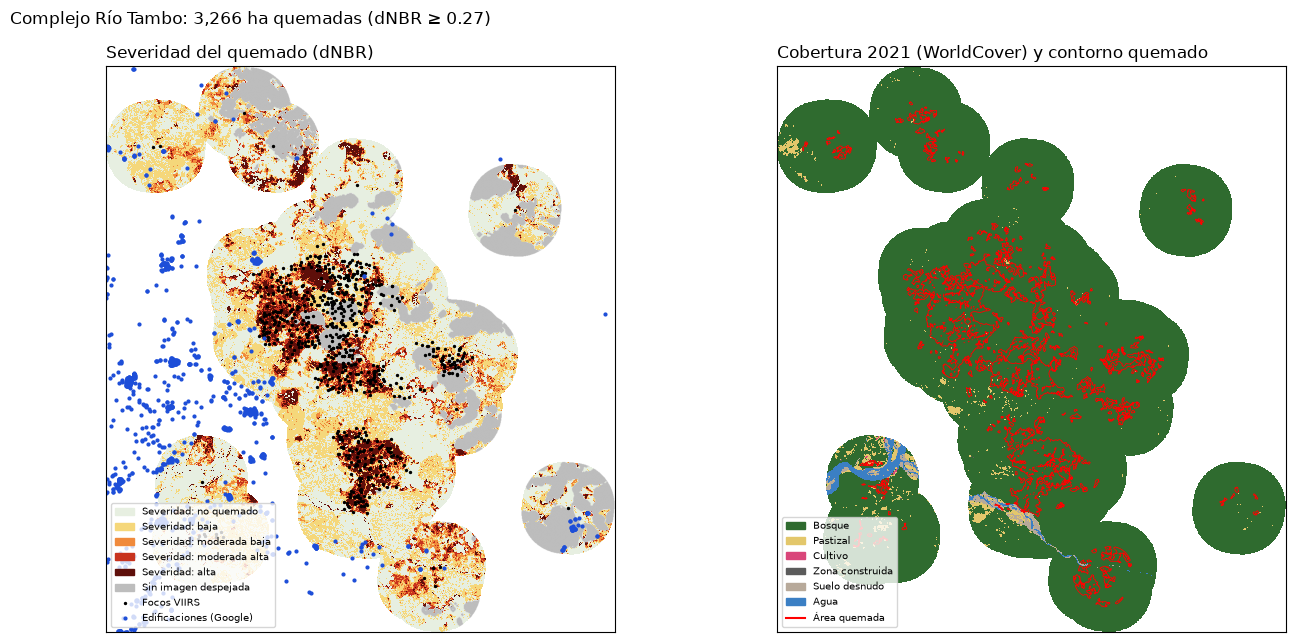

In [18]:
extent = (x0, x1, y0, y1)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
cmap_sev = ListedColormap(["#e7efe1", "#f5d77a", "#f08a3c", "#c8331e", "#5e0f0a"])
sev_vis = np.where(observado, sev, np.nan)
axes[0].imshow(sev_vis, cmap=cmap_sev, norm=BoundaryNorm(np.arange(-0.5, 5.5), 5), extent=extent,
               interpolation="nearest")
axes[0].imshow(np.where(observado | ~mascara_zona, np.nan, 1), cmap=ListedColormap(["#bdbdbd"]), extent=extent)
focos_rt.to_crs(CRS_UTM).plot(ax=axes[0], color="black", markersize=2, label="Focos VIIRS")
edif_rt.centroid.plot(ax=axes[0], color="#1d4ed8", markersize=4, label="Edificaciones (Google)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap_sev.colors] +
               [plt.Rectangle((0, 0), 1, 1, color="#bdbdbd")] + axes[0].get_legend_handles_labels()[0],
               labels=[f"Severidad: {n.lower()}" for n in NOMBRES_SEV] + ["Sin imagen despejada"] +
               axes[0].get_legend_handles_labels()[1], loc="lower left", fontsize=7)
axes[0].set_title("Severidad del quemado (dNBR)", loc="left")

wc_vis = np.where(mascara_zona, wc, 0).astype(float)
clases_presentes = [c for c in CLASES_WC if (wc_vis == c).any()]
cmap_wc = ListedColormap([COLORES_WC[CLASES_WC[c]] for c in clases_presentes])
indice = np.full(wc.shape, np.nan)
for i, c in enumerate(clases_presentes):
    indice[wc_vis == c] = i
axes[1].imshow(indice, cmap=cmap_wc, norm=BoundaryNorm(np.arange(-0.5, len(clases_presentes) + 0.5), len(clases_presentes)),
               extent=extent, interpolation="nearest")
axes[1].contour(np.flipud(quemado.astype(float)), levels=[0.5], colors="red", linewidths=0.6,
                extent=extent, origin="lower")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORES_WC[CLASES_WC[c]]) for c in clases_presentes] +
               [plt.Line2D([], [], color="red")],
               labels=[CLASES_WC[c] for c in clases_presentes] + ["Área quemada"], loc="lower left", fontsize=7)
axes[1].set_title("Cobertura 2021 (WorldCover) y contorno quemado", loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle(f"Complejo Río Tambo: {area_quemada:,.0f} ha quemadas (dNBR ≥ {UMBRAL_DNBR})", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIG / "rio_tambo_dnbr.png", dpi=150)
plt.show()

### 7.6 Imágenes para el visor del tablero: antes y después en falso color

Falso color SWIR2-NIR-rojo (B12, B08, B04): la vegetación sana se ve verde y lo quemado, marrón rojizo.
Uso la misma regla de compuesto que para el NBR (la observación sin nubes más reciente) y el mismo
estiramiento de color en las dos fechas, para que se puedan comparar.

In [19]:
from PIL import Image


def compuesto_color(items):
    rgb = np.full((3, ALTO, ANCHO), np.nan, dtype="float32")
    for it in sorted(items, key=lambda i: i["properties"]["datetime"], reverse=True):
        nube = binary_dilation(np.isin(scl[it["id"]], NUBE), iterations=3)
        usar = np.isnan(rgb[0]) & np.isin(scl[it["id"]], VALIDO) & ~nube
        if usar.sum() < 100:
            continue
        for b, (banda, res) in enumerate([("swir22", Resampling.nearest), ("nir", Resampling.average),
                                          ("red", Resampling.average)]):
            capa = reflectancia(it, banda, res)
            rgb[b][usar] = capa[usar]
    return rgb


ruta_color = PROC / f"rio_tambo_color_v1_{ANCHO}x{ALTO}_{x0:.0f}_{y1:.0f}.npz"
if ruta_color.exists():
    guardado = np.load(ruta_color)
    color_antes, color_despues = guardado["antes"], guardado["despues"]
else:
    color_antes = compuesto_color(en_periodo("2026-09-15", "2026-10-03"))
    color_despues = compuesto_color(en_periodo("2026-10-13", f"{FIN:%Y-%m-%d}"))
    np.savez_compressed(ruta_color, antes=color_antes, despues=color_despues)

ambos = np.concatenate([color_antes, color_despues], axis=2)
lo, hi = np.nanpercentile(ambos, 2, axis=(1, 2)), np.nanpercentile(ambos, 98, axis=(1, 2))


def a_jpg(rgb, nombre):
    norm = np.clip((rgb - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1) ** 0.85
    img = np.where(np.isnan(norm), 0.85, norm)                    # sin dato: gris claro
    img = np.where(mascara_zona[None], img, 0.93)                  # fuera de la zona: más claro aún
    Image.fromarray((img.transpose(1, 2, 0) * 255).astype("uint8")).save(DOCS / "img" / nombre, quality=86)


(DOCS / "img").mkdir(exist_ok=True)
a_jpg(color_antes, "rt_antes.jpg")
a_jpg(color_despues, "rt_despues.jpg")

borde = binary_dilation(quemado, iterations=2) & ~quemado
contorno = np.zeros((ALTO, ANCHO, 4), dtype="uint8")
contorno[quemado] = (255, 60, 40, 70)
contorno[borde] = (255, 45, 30, 255)
Image.fromarray(contorno).save(DOCS / "img" / "rt_contorno.png", optimize=True)

COLORES_SEV = [(0, 0, 0, 0), (245, 215, 122, 150), (240, 138, 60, 200), (200, 51, 30, 230), (94, 15, 10, 240)]
severidad_png = np.zeros((ALTO, ANCHO, 4), dtype="uint8")
for i, c in enumerate(COLORES_SEV):
    severidad_png[(sev == i) & observado & cerca_focos] = c
Image.fromarray(severidad_png).save(DOCS / "img" / "rt_severidad.png", optimize=True)

fil_f, col_f = rasterio.transform.rowcol(TRANSF, *focos_rt.to_crs(CRS_UTM).pipe(lambda g: (g.geometry.x, g.geometry.y)))
visor = {
    "ancho": ANCHO, "alto": ALTO,
    "edificios": [[int(c), int(f), int(d)] for c, f, d in zip(col[dentro_grilla], fil[dentro_grilla], edif_rt.dist_quemado_m)
                  if mascara_zona[f, c]],
    "focos": [[int(c), int(f), f"{h:%Y-%m-%d}"] for c, f, h in zip(col_f, fil_f, focos_rt.hora_lima)
              if 0 <= f < ALTO and 0 <= c < ANCHO],
    "fecha_antes": pd.Series(fecha_antes[mascara_zona]).mode().iat[0].isoformat()[:10],
    "fecha_despues": pd.Series(fecha_despues[mascara_zona]).dropna().mode().iat[0].isoformat()[:10],
}
print(f"Visor: {len(visor['edificios'])} edificaciones y {len(visor['focos'])} focos dentro de la zona; "
      f"imágenes de {visor['fecha_antes']} y {visor['fecha_despues']}")

Visor: 482 edificaciones y 739 focos dentro de la zona; imágenes de 2026-10-03 y 2026-10-20


### 7.7 Lo que dice el Estado: daños oficiales y acciones del último mes

El reporte complementario n.º 14680 del COEN-INDECI (21/10/2026, 17:05 h) resume daños y acciones de
todos los niveles de gobierno. Pasé su cronología a una tabla (`data/acciones_estado_rio_tambo.csv`).

In [20]:
oficial = pd.Series({
    "Personas damnificadas": 23, "Personas afectadas": 84, "Personas lesionadas": 2,
    "Viviendas destruidas": 8, "Viviendas afectadas": 23,
    "Cultivos afectados (ha)": 120, "Cobertura natural destruida (ha)": 1200,
}, name="COEN al 20/10/2026")
print(oficial.to_string())
print(f"\nSatélite: {area_quemada:,.0f} ha quemadas, frente a {oficial.iloc[5] + oficial.iloc[6]:,} ha del COEN "
      f"(cultivos + cobertura natural)")

acciones = pd.read_csv(RAIZ / "data/acciones_estado_rio_tambo.csv", parse_dates=["fecha"])
acciones.groupby(["tipo", "nivel"]).size().unstack(fill_value=0)

Personas damnificadas                 23
Personas afectadas                    84
Personas lesionadas                    2
Viviendas destruidas                   8
Viviendas afectadas                   23
Cultivos afectados (ha)              120
Cobertura natural destruida (ha)    1200

Satélite: 3,266 ha quemadas, frente a 1,320 ha del COEN (cultivos + cobertura natural)


nivel,Local,Nacional,Regional
tipo,,,
Alerta,0,1,0
Ayuda humanitaria,0,2,2
Bomberos,1,2,2
Brigadas comunales,1,0,0
Coordinación,0,1,0
Evaluación,1,1,0
Medios aéreos,1,8,0
Programas sociales,0,1,0
Respuesta en terreno,2,1,0


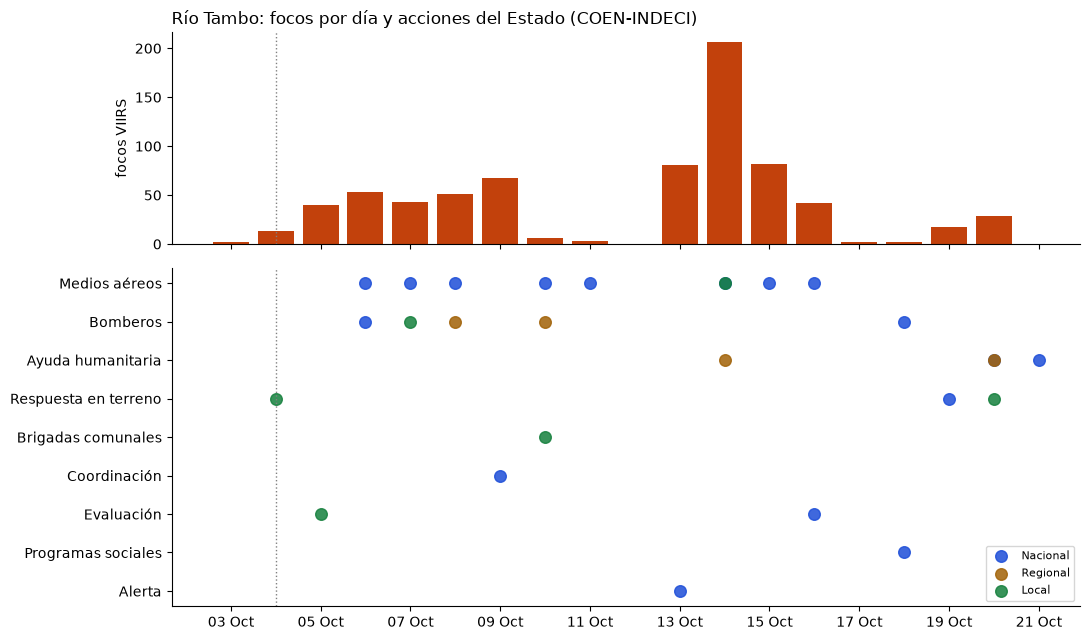

In [21]:
TIPOS = ["Medios aéreos", "Bomberos", "Ayuda humanitaria", "Respuesta en terreno", "Brigadas comunales",
         "Coordinación", "Evaluación", "Programas sociales", "Alerta"]
COLOR_NIVEL = {"Nacional": "#1d4ed8", "Regional": "#a16207", "Local": "#15803d"}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]})
dia_rt = focos_rt.groupby(focos_rt.hora_lima.dt.floor("D")).size()
ax1.bar(dia_rt.index, dia_rt.values, color="#c2410c", width=0.8)
ax1.set_ylabel("focos VIIRS")
ax1.set_title("Río Tambo: focos por día y acciones del Estado (COEN-INDECI)", loc="left")
for nivel, color in COLOR_NIVEL.items():
    sub = acciones[acciones.nivel == nivel]
    ax2.scatter(sub.fecha, [TIPOS.index(t) for t in sub.tipo], s=70, color=color, label=nivel, alpha=0.85)
ax2.set_yticks(range(len(TIPOS)), TIPOS)
ax2.invert_yaxis()
ax2.legend(loc="lower right", fontsize=8)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.axvline(pd.Timestamp("2026-10-04"), color="grey", linestyle=":", linewidth=1)
plt.tight_layout()
plt.savefig(FIG / "rio_tambo_acciones.png", dpi=150)
plt.show()

### 7.8 La ayuda de la sociedad civil: Perú Pendiente

La ONG Perú Pendiente publicó en Instagram (@perupendiente, octubre de 2026) cuánto recaudó para los
incendios y qué equipos compró para ocho comandancias departamentales del CGBVP. Transcribí sus
tablas tal como aparecen (`data/perupendiente_equipos.csv` y `data/perupendiente_totales.csv`) y las
reviso: cantidad × costo unitario, suma de ítems frente al total de cada comandancia y suma de
comandancias frente al "monto ejecutado CGBVP".

In [22]:
PP_RESUMEN = {"Monto recaudado": 501_570.18, "Monto ejecutado CGBVP": 440_341.50,
              "Monto ejecutado ayuda humanitaria": 31_434.00, "Saldo": 29_794.68}
pp_items = pd.read_csv(RAIZ / "data/perupendiente_equipos.csv")
pp_tot = pd.read_csv(RAIZ / "data/perupendiente_totales.csv")

pp_items["recalculado"] = pp_items.cantidad * pp_items.costo_unitario
print("Filas donde cantidad × costo unitario no da el costo total publicado:")
print(pp_items.loc[(pp_items.recalculado - pp_items.costo_total_publicado).abs() > 1,
                   ["departamento", "item", "cantidad", "costo_unitario", "costo_total_publicado", "recalculado"]]
      .to_string(index=False))

revision = (pp_items.groupby("comandancia", sort=False).costo_total_publicado.sum().rename("suma_de_items")
            .to_frame().join(pp_tot.set_index("comandancia")))
revision["diferencia"] = revision.total_publicado - revision.suma_de_items
print("\nSuma de ítems frente al total publicado de cada comandancia:")
print(revision.round(2).to_string())
print(f"\nSuma de los 8 totales: S/ {pp_tot.total_publicado.sum():,.2f} · "
      f"'Monto ejecutado CGBVP': S/ {PP_RESUMEN['Monto ejecutado CGBVP']:,.2f} · "
      f"recaudado − ejecutado − saldo = S/ {PP_RESUMEN['Monto recaudado'] - PP_RESUMEN['Monto ejecutado CGBVP'] - PP_RESUMEN['Monto ejecutado ayuda humanitaria'] - PP_RESUMEN['Saldo']:,.2f}")

Filas donde cantidad × costo unitario no da el costo total publicado:
departamento                 item  cantidad  costo_unitario  costo_total_publicado  recalculado
       CUSCO Mfire 2 con remolque         4         13579.0                54280.0      54316.0
       PASCO Mfire 2 con remolque         4         13570.0                27140.0      54280.0

Suma de ítems frente al total publicado de cada comandancia:
                                                   suma_de_items departamento  total_publicado  diferencia
comandancia                                                                                               
IX Comandancia Departamental de Bomberos de Cusco       108750.5        CUSCO         135890.5     27140.0
XIX Comandancia Departamental Apurímac (Abancay)         73803.8     APURIMAC          73803.8         0.0
XXVI Comandancia Departamental Ayacucho                  40293.7     AYACUCHO          34984.7     -5309.0
X Comandancia Departamental Junín Centro     

**¿La ayuda fue a donde está el fuego?** Cruzo el monto publicado por departamento con los incendios
del último mes. Ojo: la ONG trabaja con las comandancias del CGBVP, y en la Amazonía (Ucayali,
Loreto, Madre de Dios) gran parte del fuego son quemas agrícolas lejos de cualquier compañía.

In [23]:
fuego_dep = focos.groupby("NOMBDEP").size().rename("focos").to_frame().join(
    grandes.groupby("departamento").agg(incendios_100ha=("focos", "size"), huella_ha=("huella_ha", "sum"),
                                         edif_1km=("edif_1km", "sum")))
ayuda_dep = fuego_dep.join(pp_tot.groupby("departamento").total_publicado.sum().rename("perupendiente_soles"))
ayuda_dep = ayuda_dep.fillna({"incendios_100ha": 0, "huella_ha": 0, "perupendiente_soles": 0})
ayuda_dep["soles_por_ha"] = ayuda_dep.perupendiente_soles / ayuda_dep.huella_ha.where(ayuda_dep.huella_ha > 0)
ayuda_dep = ayuda_dep.sort_values("huella_ha", ascending=False)
ayuda_dep.head(14).round(1)

,focos,incendios_100ha,huella_ha,edif_1km,perupendiente_soles,soles_por_ha
NOMBDEP,,,,,,
UCAYALI,10979,141.0,22746.1,18.0,0.0,0.0
CUSCO,4220,63.0,19427.5,5366.0,135890.5,7.0
APURIMAC,2828,44.0,18696.8,802.0,73803.8,3.9
HUANUCO,6663,87.0,14715.2,127.0,33384.7,2.3
JUNIN,5729,57.0,14446.6,92.0,61324.7,4.2
PUNO,2132,41.0,12629.2,307.0,67184.7,5.3
AYACUCHO,2140,37.0,9074.8,429.0,34984.7,3.9
AREQUIPA,1357,23.0,8942.4,51.0,0.0,0.0
ANCASH,1935,45.0,8666.8,0.0,34984.7,4.0


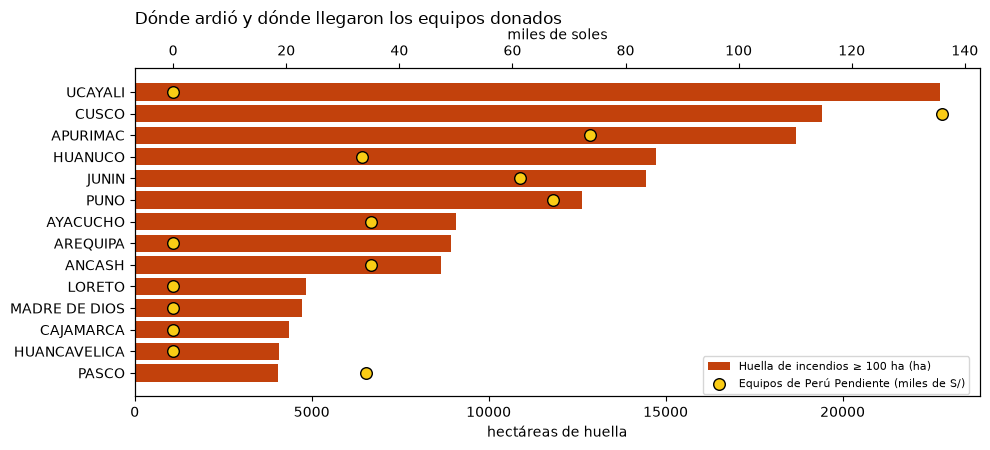

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.6))
top_dep = ayuda_dep.head(14)
ax.barh(top_dep.index[::-1], top_dep.huella_ha[::-1], color="#c2410c", label="Huella de incendios ≥ 100 ha (ha)")
ax2 = ax.twiny()
ax2.scatter(top_dep.perupendiente_soles[::-1] / 1000, top_dep.index[::-1], color="#facc15", edgecolor="black",
            s=70, zorder=3, label="Equipos de Perú Pendiente (miles de S/)")
ax.set_xlabel("hectáreas de huella")
ax2.set_xlabel("miles de soles")
ax.set_title("Dónde ardió y dónde llegaron los equipos donados", loc="left", pad=32)
fig.legend(loc="lower right", fontsize=8, bbox_to_anchor=(0.98, 0.12))
plt.tight_layout()
plt.savefig(FIG / "ayuda_vs_fuego.png", dpi=150)
plt.show()

## 8. Exportar para el tablero web (`docs/`)

In [25]:
def a_lista(df):
    return json.loads(df.to_json(orient="records", date_format="iso", force_ascii=False))


ranking = grandes.to_crs(4326)
ranking = ranking.assign(lon=ranking.centroid.x, lat=ranking.centroid.y).reset_index()
cols_rank = ["incendio", "departamento", "provincia", "distrito", "huella_ha", "focos", "inicio", "fin", "activo_24h",
             "bomberos", "dist_bomberos_km", "tramo_bomberos", "edif_dentro", "edif_1km", "edif_3km",
             "cobertura_principal", "pct_principal", "lon", "lat"]
ranking = ranking[cols_rank].assign(tramo_bomberos=lambda d: d.tramo_bomberos.astype(str))

zona_4326 = zona_utm.to_crs(4326).total_bounds
datos = {
    "corte": f"{focos.hora_lima.max():%Y-%m-%d %H:%M}",
    "periodo": [f"{INICIO:%Y-%m-%d}", f"{FIN:%Y-%m-%d}"],
    "resumen": {"focos": len(focos), "incendios": len(incendios), "grandes": len(grandes),
                "activos_24h": int(grandes.activo_24h.sum()), "estaciones_bomberos": len(bomberos)},
    "por_dia": [{"dia": f"{d:%Y-%m-%d}", "focos": int(n)} for d, n in por_dia.items()],
    "cobertura_nacional": [{"clase": c, "ha": round(v)} for c, v in ha_por_clase.items() if v > 0],
    "tramos_bomberos": a_lista(grandes.groupby("tramo_bomberos", observed=False)
                              .agg(incendios=("focos", "size"), huella_ha=("huella_ha", "sum")).round(0)
                              .reset_index().astype({"tramo_bomberos": str})),
    "incendios": a_lista(ranking.round(4)),
    "bomberos": [{"nombre": b.nombre, "lon": round(b.geometry.x, 5), "lat": round(b.geometry.y, 5)}
                 for b in bomberos.to_crs(4326).itertuples()],
    "rio_tambo": {
        "huella_ha": round(complejo.huella_ha.sum()), "focos": len(focos_rt),
        "area_quemada_ha": round(area_quemada), "sin_ver_ha": round(sin_ver),
        "severidad": [{"clase": k, "ha": round(v)} for k, v in tabla_sev.items()],
        "que_se_quemo": [{"clase": k, "ha": round(v.ha), "pct": v["%"]} for k, v in que_se_quemo.iterrows()],
        "edificaciones": {k: int(v) for k, v in edif_tabla.items()},
        "bomberos_cercanos": [{"nombre": r.nombre, "km": round(r.km)} for r in bomberos_rt.itertuples()],
        "oficial": {k: int(v) for k, v in oficial.items()},
        "acciones": a_lista(acciones.assign(fecha=acciones.fecha.dt.strftime("%Y-%m-%d"))),
        "focos_por_dia": [{"dia": f"{d:%Y-%m-%d}", "focos": int(n)} for d, n in dia_rt.items()],
        "imagenes": a_lista(imagenes),
        "limites": [round(v, 5) for v in zona_4326],
        "visor": visor,
    },
    "perupendiente": {
        "resumen": PP_RESUMEN,
        "comandancias": a_lista(revision.reset_index().round(2)),
        "items": a_lista(pp_items.drop(columns="recalculado")),
        "por_departamento": a_lista(ayuda_dep.head(14).rename_axis("departamento").reset_index().round(1)),
    },
}
deps_simple = departamentos.assign(geometry=departamentos.simplify(0.01))
datos["departamentos"] = json.loads(deps_simple.to_json(to_wgs84=True))
datos["departamentos"]["features"] = [  # 4 decimales (~10 m) bastan para un mapa nacional
    {"type": "Feature", "properties": {"NOMBDEP": f["properties"]["NOMBDEP"]},
     "geometry": json.loads(json.dumps(f["geometry"]), parse_float=lambda x: round(float(x), 4))}
    for f in datos["departamentos"]["features"]]
# Hectáreas de cada cobertura dentro de la huella de cada incendio, para el mapa por cobertura
comp_ha = comp.mul(grandes.huella_ha, axis=0)
datos["cobertura_por_incendio"] = {str(i): {c: round(v, 1) for c, v in fila.items() if v >= 0.5}
                                   for i, fila in comp_ha.iterrows()}
# Forma de cada huella para el zoom del tablero: simplificada a ~150 m, con 4 decimales y el anillo
# exterior en sentido horario, que es como d3 entiende el interior de un polígono
formas = grandes.to_crs(4326).geometry.simplify(0.0015).to_numpy()
formas = shapely.orient_polygons(shapely.set_precision(formas, 1e-4), exterior_cw=True)
datos["huellas"] = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {"incendio": int(i)}, "geometry": shapely.geometry.mapping(g)}
    for i, g in zip(grandes.index, formas) if not g.is_empty]}
(DOCS / "datos.js").write_text("window.DATOS = " + json.dumps(datos, ensure_ascii=False) + ";\n", encoding="utf-8")
(DOCS / "img").mkdir(exist_ok=True)
for nombre in ["rio_tambo_dnbr.png", "rio_tambo_acciones.png", "mapa_nacional.png"]:
    (DOCS / "img" / nombre).write_bytes((FIG / nombre).read_bytes())
grandes.to_crs(4326).assign(geometry=lambda d: d.simplify(0.0005)).drop(columns=["inicio", "fin"]).assign(
    inicio=grandes.inicio.dt.strftime("%Y-%m-%d %H:%M"), fin=grandes.fin.dt.strftime("%Y-%m-%d %H:%M"),
    tramo_bomberos=grandes.tramo_bomberos.astype(str)).to_file(PROC / "incendios_100ha.geojson", driver="GeoJSON")
print("Listo:", DOCS / "datos.js", PROC / "incendios_100ha.geojson")

Listo: C:\GitHub\reto-c-incendios\docs\datos.js C:\GitHub\reto-c-incendios\data\processed\incendios_100ha.geojson


## 9. Hallazgos y limitaciones

Los números de esta sección se imprimen con los datos del corte, para copiarlos al README.

In [26]:
lejos = grandes[grandes.dist_bomberos_km > 30]
con_casas = grandes.dropna(subset=["edif_1km"])
print(f"1. Ardió sobre todo {ha_por_clase.index[0].lower()}: {ha_por_clase.iloc[0] / ha_por_clase.sum():.0%} "
      f"de la huella de los {len(grandes)} incendios ≥ 100 ha ({ha_por_clase.iloc[0]:,.0f} ha).")
print(f"2. {len(lejos)} de {len(grandes)} incendios ≥ 100 ha ({len(lejos) / len(grandes):.0%}) estaban a más de "
      f"30 km en línea recta de una compañía de bomberos; mediana: {grandes.dist_bomberos_km.median():.0f} km.")
print(f"3. En {(con_casas.edif_1km > 0).sum()} de los {len(con_casas)} incendios más grandes había edificaciones a "
      f"≤ 1 km de la zona con fuego ({int(con_casas.edif_1km.sum()):,} en total).")
print(f"4. Río Tambo: {area_quemada:,.0f} ha quemadas; "
      + ", ".join(f"{k.lower()} {v.ha:,.0f} ha ({v['%']:.0f} %)" for k, v in que_se_quemo.head(3).iterrows())
      + f"; {edif_tabla.iloc[0]} edificaciones dentro y {edif_tabla.iloc[2]} a ≤ 1 km del área quemada.")

1. Ardió sobre todo pastizal: 56% de la huella de los 730 incendios ≥ 100 ha (90,376 ha).
2. 503 de 730 incendios ≥ 100 ha (69%) estaban a más de 30 km en línea recta de una compañía de bomberos; mediana: 45 km.
3. En 20 de los 20 incendios más grandes había edificaciones a ≤ 1 km de la zona con fuego (7,722 en total).
4. Río Tambo: 3,266 ha quemadas; bosque 3,247 ha (99 %), pastizal 16 ha (0 %), suelo desnudo 2 ha (0 %); 10 edificaciones dentro y 287 a ≤ 1 km del área quemada.
